# Wpływ hiperparametrów architektonicznych oraz regularyzacji na proces uczenia i jakość estymacji wag


In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils.phase import Phase
from utils.model_utils import compare_mean_mae_models, compare_kendal_tau_models
from data_augmentation.monte_carlo_loader import MonteCarloLoader
from model.trainers.dense_monte_carlo_trainer import DenseMonteCarloTrainer
from model.trainers.trainer import load_model, get_hyperparameter_model_str
from metrics.evaluator import Evaluator

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Urządzenie: {device}')
if device.type == 'cuda':
    print(f'Karta graficzna: {torch.cuda.get_device_name(0)}')

CRITERIA_NUM = 5
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']
loader = MonteCarloLoader()
evaluator = Evaluator()

test_matrices = {}
true_weights = {}
for stratum in STRATA:
    mats, wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=None
    )
    test_matrices[stratum] = mats
    true_weights[stratum] = wts


Urządzenie: cuda
Karta graficzna: NVIDIA GeForce RTX 2060


In [2]:
def load_and_predict_configs(configs, test_matrices, device, criteria_num=CRITERIA_NUM):
    predicted_weights = {s: [] for s in STRATA}
    model_names = []
    histories = {}
    models = {}

    for p, label in configs:
        model, history = load_model(
            params=p,
            model_type="dense_hiperparameters_exp",
            device=device,
            n_criteria=criteria_num
        )
        trainer = DenseMonteCarloTrainer(model, None, None, device)
        model_names.append(label)
        histories[label] = history
        models[label] = model

        for s in STRATA:
            preds = trainer.predict_batch(test_matrices[s])
            predicted_weights[s].append(preds)

    return predicted_weights, model_names, histories, models

def plot_histories_metric(histories, metric_key, title, ylabel, xlabel='Epoka', figsize=(10, 6), ylim=None, legend_title=""):
    sns.set_theme(style='whitegrid')
    plt.figure(figsize=figsize)
    palette = sns.color_palette('tab10', n_colors=len(histories))

    for (label, h), color in zip(histories.items(), palette):
        values = h.get(metric_key, [])
        if len(values) > 0:
            epochs = np.arange(1, len(values) + 1)
            plt.plot(epochs, values, label=label, linewidth=2, color=color)

    plt.title(title, fontsize=13, pad=10)
    plt.xlabel(xlabel, fontsize=11)
    plt.ylabel(ylabel, fontsize=11)
    if ylim is not None:
        plt.ylim(ylim)
    plt.legend(title=legend_title, frameon=True, fontsize=9)
    plt.tight_layout()
    plt.show()

def compute_overall_metrics(true_weights, predicted_weights, model_names):
    mae_list = []
    tau_list = []

    for idx, name in enumerate(model_names):
        all_true = []
        all_pred = []
        for s in STRATA:
            all_true.append(true_weights[s])
            all_pred.append(predicted_weights[s][idx])
        y_true_all = np.vstack(all_true)
        y_pred_all = np.vstack(all_pred)

        mae_scores, tau_scores, _, _ = evaluator.evaluate_batch(y_true_all, y_pred_all)
        mae_list.append(float(np.mean(mae_scores)))
        tau_list.append(float(np.mean(tau_scores)))

    return mae_list, tau_list

def plot_param_trend(param_values, mae_values, tau_values, param_name, x_scale='linear', figsize=(13, 5)):
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    axes[0].plot(param_values, mae_values, marker='o', color='crimson', linewidth=2, markersize=6)
    axes[0].set_title(f'Błąd MAE w zależności od {param_name}', fontsize=12, pad=10)
    axes[0].set_xlabel(param_name, fontsize=11)
    axes[0].set_ylabel('Średni błąd MAE (niższy = lepszy)', fontsize=11)
    axes[0].set_xscale(x_scale)
    for x, y in zip(param_values, mae_values):
        axes[0].annotate(f'{y:.4f}', (x, y), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9)

    axes[1].plot(param_values, tau_values, marker='s', color='navy', linewidth=2, markersize=6)
    axes[1].set_title(f'Korelacja Kendall Tau w zależności od {param_name}', fontsize=12, pad=10)
    axes[1].set_xlabel(param_name, fontsize=11)
    axes[1].set_ylabel('Kendall Tau (wyższy = lepszy)', fontsize=11)
    axes[1].set_xscale(x_scale)
    for x, y in zip(param_values, tau_values):
        axes[1].annotate(f'{y:.4f}', (x, y), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9)

    plt.tight_layout()
    plt.show()


## 1. Wpływ parametrów architektonicznych


### 1.1. Liczba warstw ukrytych (Layers)


In [3]:
layers_configs = [
    ({'layers': 3, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '3'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '4'),
    ({'layers': 5, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '5'),
    ({'layers': 6, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '6'),
    ({'layers': 7, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '7'),
    ({'layers': 8, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '8'),
]

pred_weights_layers, names_layers, hist_layers, _ = load_and_predict_configs(
    layers_configs, test_matrices, device
)


History and model: lay3_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay5_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay6_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay7_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay8_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp


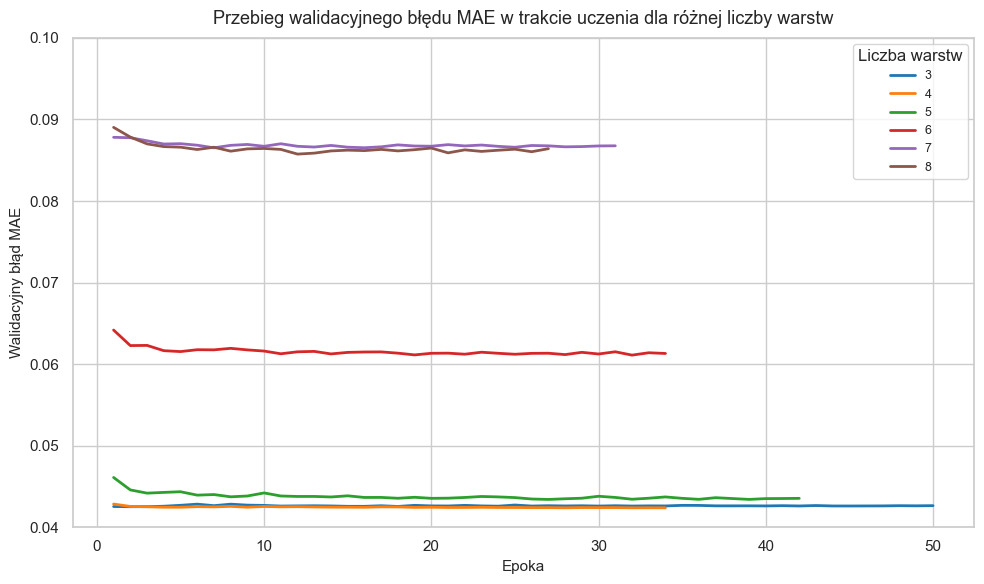

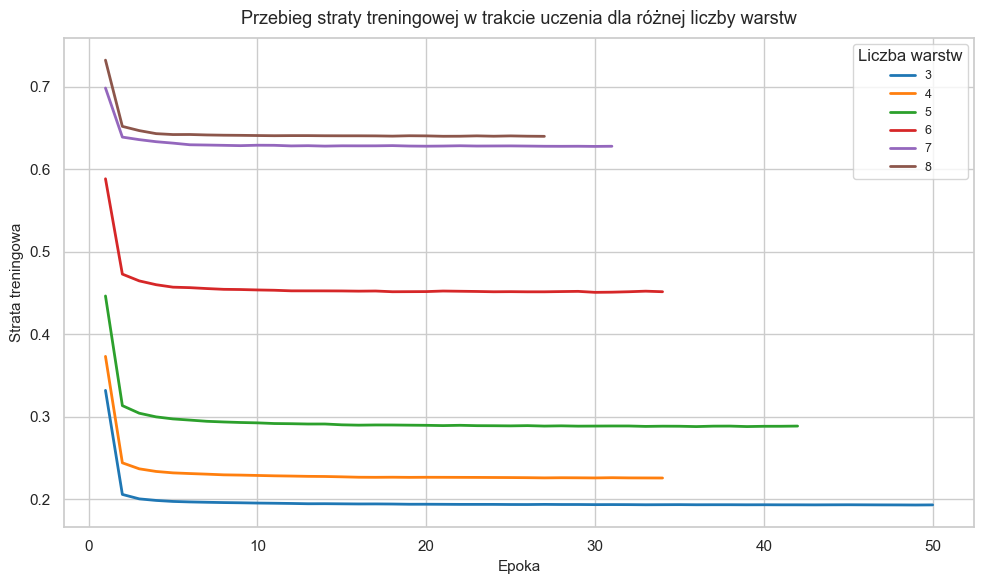

In [4]:
plot_histories_metric(
    hist_layers,
    metric_key='valid_mae',
    title='Przebieg walidacyjnego błędu MAE w trakcie uczenia dla różnej liczby warstw',
    ylabel='Walidacyjny błąd MAE',
    ylim=(0.04, 0.10),
    legend_title='Liczba warstw'
)

plot_histories_metric(
    hist_layers,
    metric_key='train_loss',
    title='Przebieg straty treningowej w trakcie uczenia dla różnej liczby warstw',
    ylabel='Strata treningowa',
    legend_title='Liczba warstw'
)


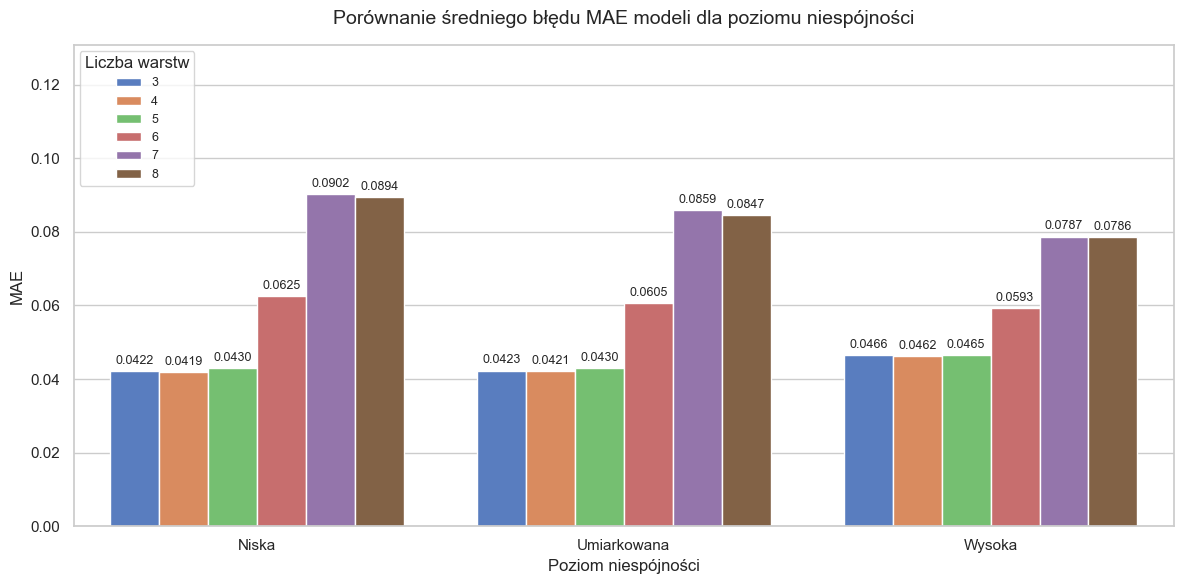

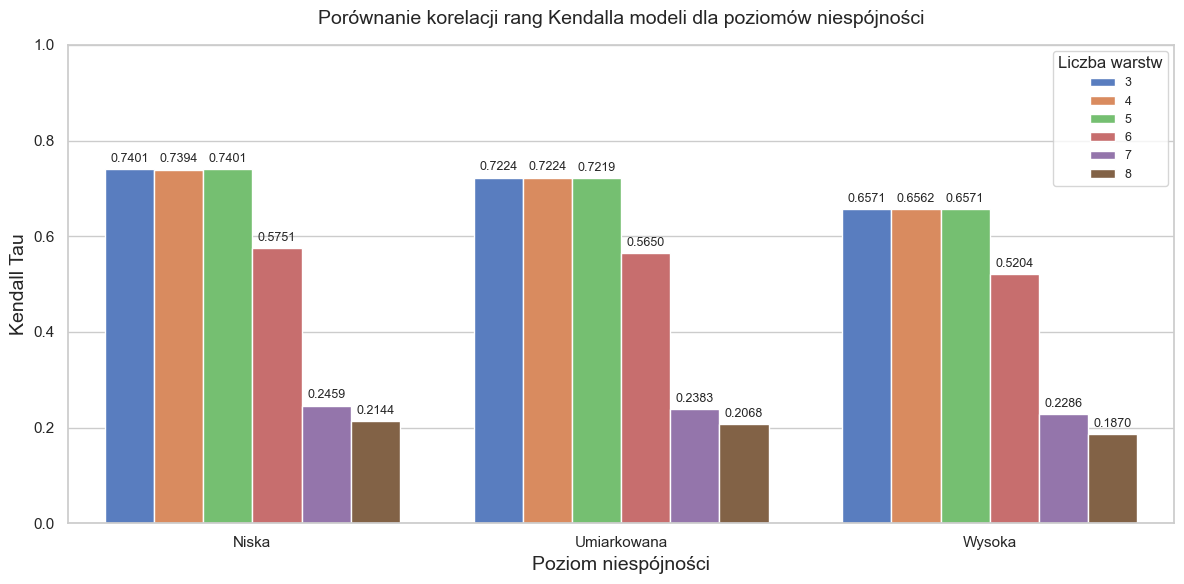

In [5]:
df_mae_layers = compare_mean_mae_models(true_weights, pred_weights_layers, names_layers, legend_title='Liczba warstw')
df_tau_layers = compare_kendal_tau_models(true_weights, pred_weights_layers, names_layers, legend_title='Liczba warstw')


### 1.2. Współczynnik ekspansji pierwszej warstwy (Expansion Factor)


In [6]:
exp_configs = [
    ({'layers': 4, 'expansion_factor': 1, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '1'),
    ({'layers': 4, 'expansion_factor': 2, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '2'),
    ({'layers': 4, 'expansion_factor': 4, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '4'),
    ({'layers': 4, 'expansion_factor': 6, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '6'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '12'),
    ({'layers': 4, 'expansion_factor': 24, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '24'),
    ({'layers': 4, 'expansion_factor': 52, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, '52'),
]

pred_weights_exp, names_exp, hist_exp, _ = load_and_predict_configs(
    exp_configs, test_matrices, device
)


History and model: lay4_exp1_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp2_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp4_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp6_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp24_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp52_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp


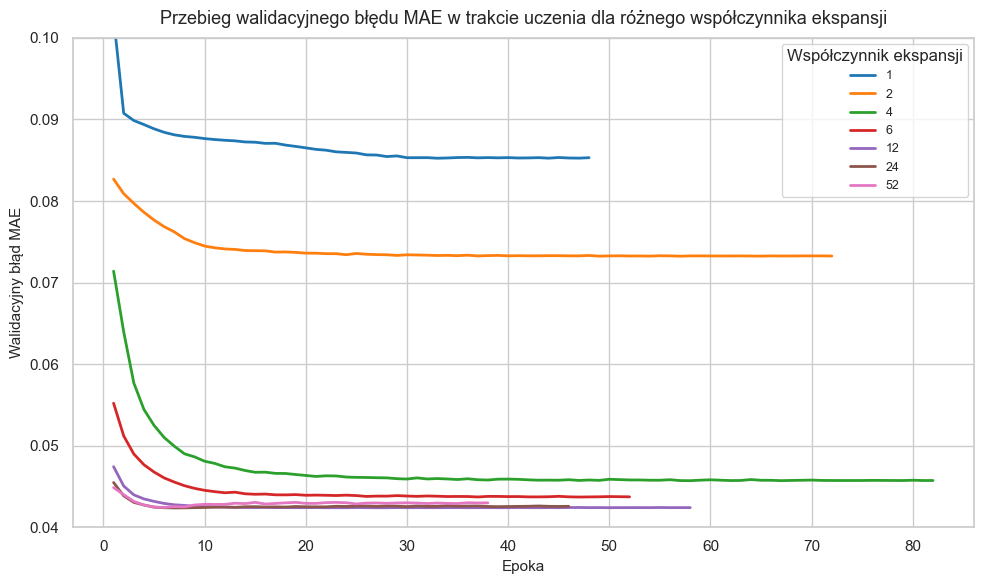

In [7]:
plot_histories_metric(
    hist_exp,
    metric_key='valid_mae',
    title='Przebieg walidacyjnego błędu MAE w trakcie uczenia dla różnego współczynnika ekspansji',
    ylabel='Walidacyjny błąd MAE',
    ylim=(0.04, 0.10),
    legend_title='Współczynnik ekspansji'
)


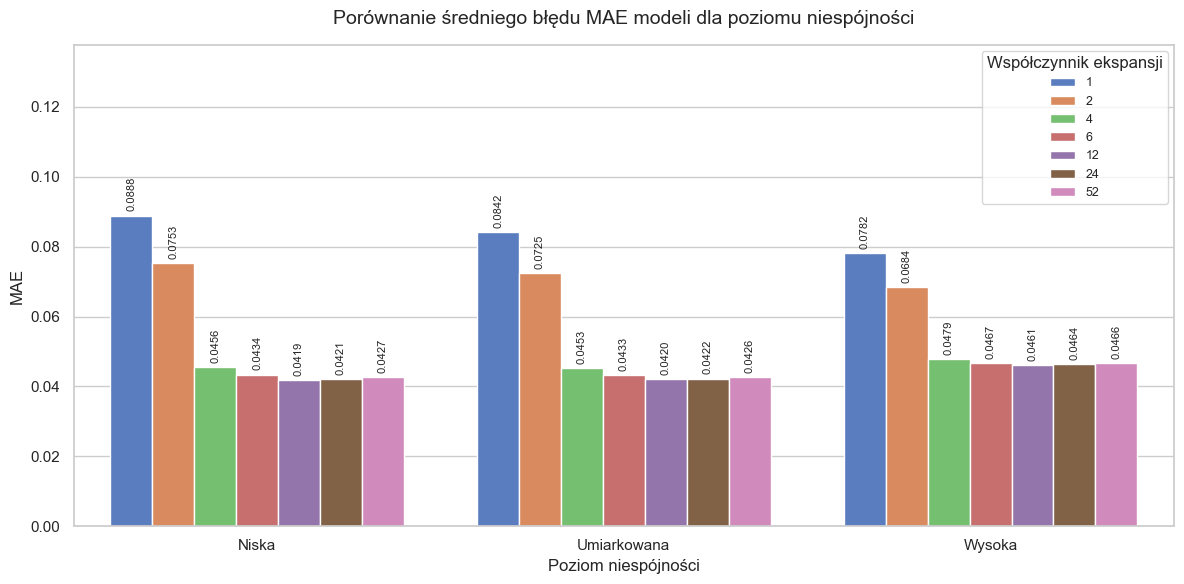

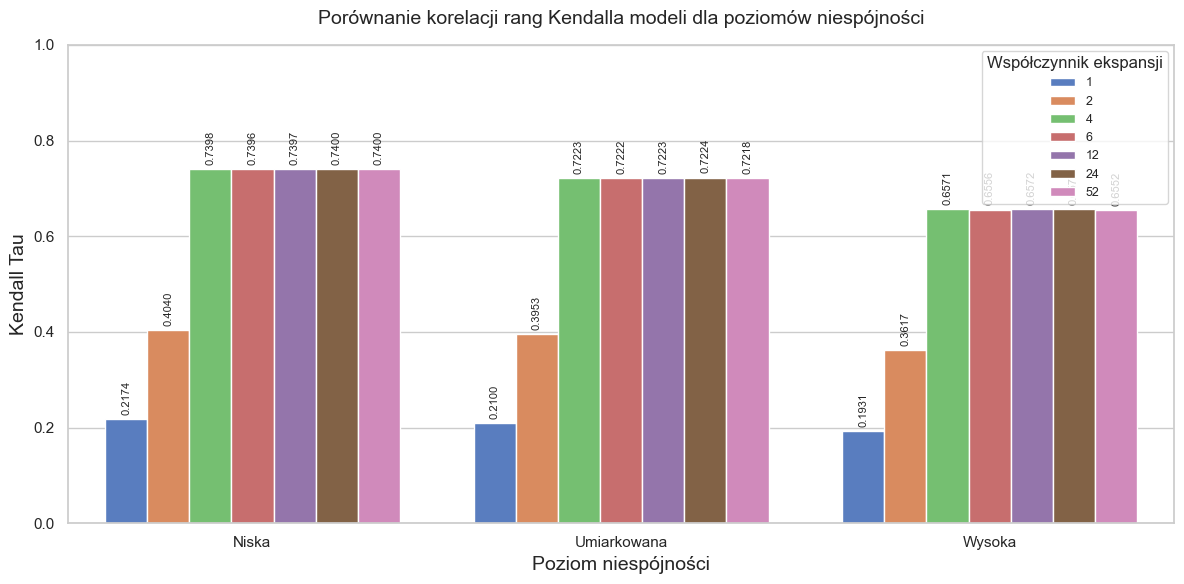

In [8]:
df_mae_exp = compare_mean_mae_models(true_weights, pred_weights_exp, names_exp, legend_title='Współczynnik ekspansji', legend_loc='upper right')
df_tau_exp = compare_kendal_tau_models(true_weights, pred_weights_exp, names_exp, legend_title='Współczynnik ekspansji')


## 2. Wpływ mechanizmów regularyzacji


### 2.1. Regularyzacja Dropout (dropout_rate)


In [9]:
dropout_configs = [
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.0, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '0.0'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.1, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '0.1'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '0.2'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.3, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '0.3'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '0.4'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.5, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, '0.5'),
]

pred_weights_drop, names_drop, hist_drop, _ = load_and_predict_configs(
    dropout_configs, test_matrices, device
)


History and model: lay4_exp12_drop0_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop1000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop3000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop4000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop5000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp


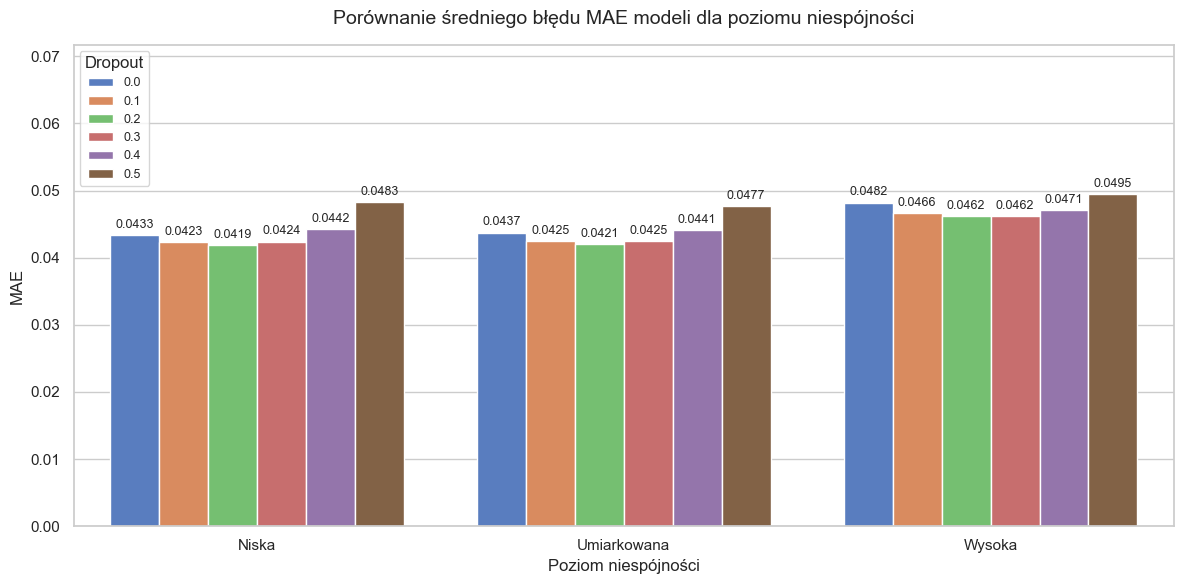

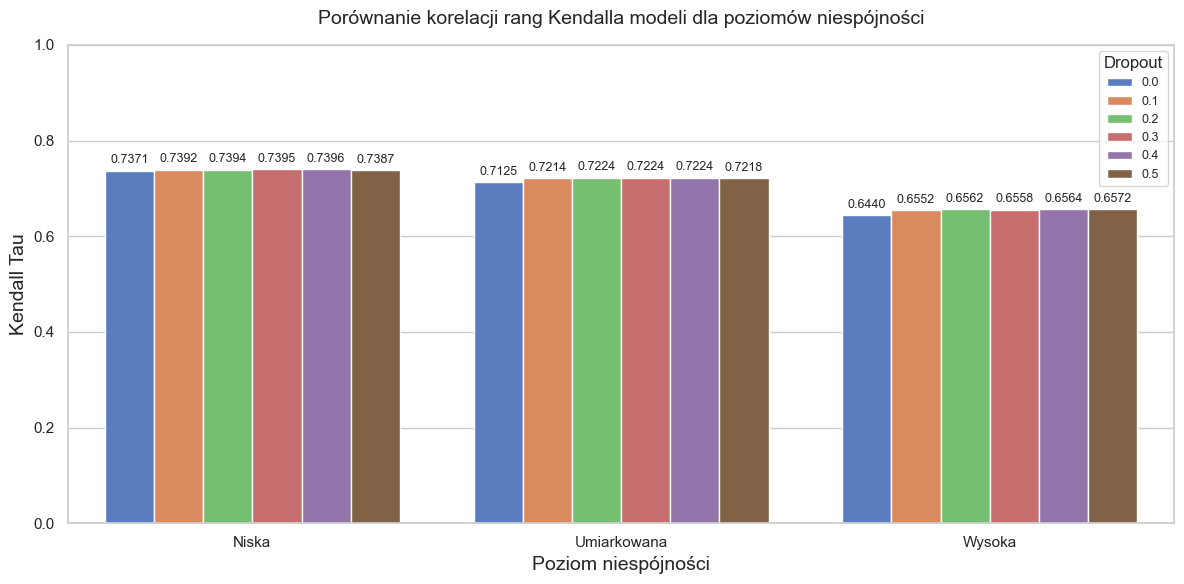

In [10]:
df_mae_drop = compare_mean_mae_models(true_weights, pred_weights_drop, names_drop, legend_title='Dropout')
df_tau_drop = compare_kendal_tau_models(true_weights, pred_weights_drop, names_drop, legend_title='Dropout')


### 2.2. Normalizacja wsadowa (Batch Normalization)


In [18]:
bn_configs = [
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': False}, 'Bez batch_norm'),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': True}, 'Z batch_norm'),
]

pred_weights_bn, names_bn, hist_bn, _ = load_and_predict_configs(
    bn_configs, test_matrices, device
)


History and model: lay4_exp12_drop3000_slope1000_lr10_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp12_drop3000_slope1000_lr10_bs256_bnTrue loaded from models\dense_hiperparameters_exp


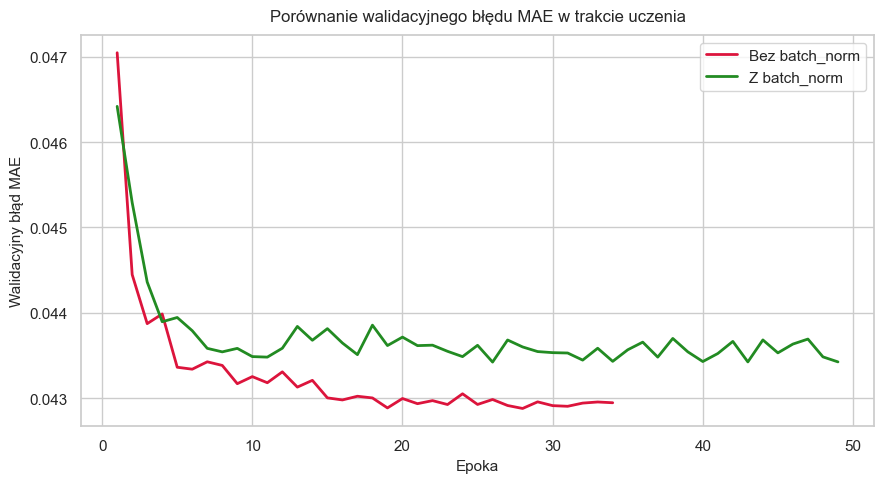

In [19]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9, 5))

palette = {'Bez batch_norm': 'crimson', 'Z batch_norm': 'forestgreen'}

for label in names_bn:
    h = hist_bn[label]
    v_mae = h.get('valid_mae', [])
    ep = np.arange(1, len(v_mae) + 1)
    plt.plot(ep, v_mae, label=label, color=palette[label], linewidth=2)

plt.title('Porównanie walidacyjnego błędu MAE w trakcie uczenia', fontsize=12, pad=10)
plt.xlabel('Epoka', fontsize=11)
plt.ylabel('Walidacyjny błąd MAE', fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 3. Łączny wpływ parametrów architektonicznych (Interakcja Layers i Expansion Factor)


In [13]:
interaction_configs = [
    ({'layers': 3, 'expansion_factor': 1, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': False}, 3, 1),
    ({'layers': 3, 'expansion_factor': 2, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': False}, 3, 2),
    ({'layers': 3, 'expansion_factor': 4, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': False}, 3, 4),
    ({'layers': 3, 'expansion_factor': 6, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': False}, 3, 6),
    ({'layers': 3, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, 3, 12),
    ({'layers': 3, 'expansion_factor': 24, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 256, 'batch_norm': False}, 3, 24),
    ({'layers': 3, 'expansion_factor': 52, 'dropout_rate': 0.3, 'negative_slope': 0.1, 'learning_rate': 0.001, 'batch_size': 256, 'batch_norm': False}, 3, 52),
    ({'layers': 4, 'expansion_factor': 1, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, 4, 1),
    ({'layers': 4, 'expansion_factor': 2, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, 4, 2),
    ({'layers': 4, 'expansion_factor': 4, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, 4, 4),
    ({'layers': 4, 'expansion_factor': 6, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, 4, 6),
    ({'layers': 4, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, 4, 12),
    ({'layers': 4, 'expansion_factor': 24, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 256, 'batch_norm': False}, 4, 24),
    ({'layers': 4, 'expansion_factor': 52, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 512, 'batch_norm': False}, 4, 52),
    ({'layers': 5, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, 5, 12),
    ({'layers': 6, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, 6, 12),
    ({'layers': 7, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, 7, 12),
    ({'layers': 8, 'expansion_factor': 12, 'dropout_rate': 0.2, 'negative_slope': 0.5, 'learning_rate': 0.001, 'batch_size': 512, 'batch_norm': False}, 8, 12),
    ({'layers': 5, 'expansion_factor': 24, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 256, 'batch_norm': False}, 5, 24),
    ({'layers': 6, 'expansion_factor': 24, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 256, 'batch_norm': False}, 6, 24),
    ({'layers': 7, 'expansion_factor': 24, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 256, 'batch_norm': False}, 7, 24),
    ({'layers': 8, 'expansion_factor': 24, 'dropout_rate': 0.4, 'negative_slope': 0.5, 'learning_rate': 0.0001, 'batch_size': 256, 'batch_norm': False}, 8, 24),
]

all_true_matrices = np.vstack([test_matrices[s] for s in STRATA])
all_true_weights = np.vstack([true_weights[s] for s in STRATA])

interaction_results = []
for p, lay, exp in interaction_configs:
    model, _ = load_model(
        params=p,
        model_type="dense_hiperparameters_exp",
        device=device,
        n_criteria=CRITERIA_NUM
    )
    trainer = DenseMonteCarloTrainer(model, None, None, device)
    preds = trainer.predict_batch(all_true_matrices)
    mae_scores, tau_scores, _, _ = evaluator.evaluate_batch(all_true_weights, preds)
    interaction_results.append({
        "layers": lay,
        "expansion_factor": exp,
        "MAE": float(np.mean(mae_scores)),
        "Kendall_Tau": float(np.mean(tau_scores))
    })

df_interaction = pd.DataFrame(interaction_results).drop_duplicates(subset=["layers", "expansion_factor"])
df_interaction.sort_values(by=["layers", "expansion_factor"], inplace=True)
df_interaction


History and model: lay3_exp1_drop3000_slope1000_lr10_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay3_exp2_drop3000_slope1000_lr10_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay3_exp4_drop3000_slope1000_lr10_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay3_exp6_drop3000_slope1000_lr10_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay3_exp12_drop2000_slope5000_lr10_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay3_exp24_drop4000_slope5000_lr1_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay3_exp52_drop3000_slope1000_lr10_bs256_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp1_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparameters_exp
History and model: lay4_exp2_drop2000_slope5000_lr1_bs512_bnFalse loaded from models\dense_hiperparamet

,layers,expansion_factor,MAE,Kendall_Tau
0,3,1,0.076477,0.390189
1,3,2,0.052424,0.718653
2,3,4,0.044465,0.719671
3,3,6,0.043099,0.720107
4,3,12,0.042676,0.722960
5,3,24,0.042485,0.723040
6,3,52,0.043654,0.718418
7,4,1,0.085442,0.211277
8,4,2,0.073213,0.395449
9,4,4,0.045699,0.722751


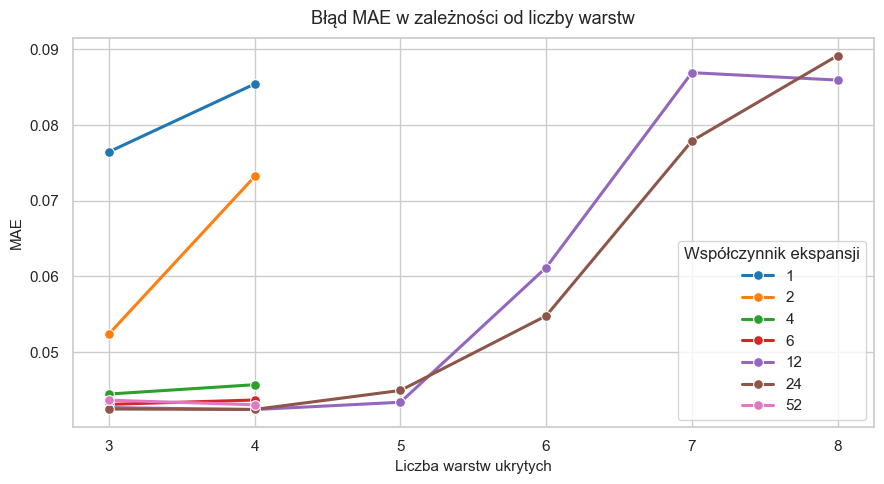

In [14]:
from matplotlib.ticker import ScalarFormatter

exp_values = [1, 2, 4, 6, 12, 24, 52]

df_plot = df_interaction.copy()
df_plot["expansion_factor_str"] = pd.Categorical(
    df_plot["expansion_factor"].astype(str),
    categories=[str(v) for v in exp_values],
    ordered=True
)
df_plot["layers_str"] = df_plot["layers"].astype(str)

palette_exp = sns.color_palette("tab10", n_colors=len(exp_values))

sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=df_plot,
    x="layers",
    y="MAE",
    hue="expansion_factor_str",
    marker="o",
    linewidth=2.2,
    markersize=7,
    palette=palette_exp
)
plt.title("Błąd MAE w zależności od liczby warstw", fontsize=13, pad=10)
plt.xlabel("Liczba warstw ukrytych", fontsize=11)
plt.ylabel("MAE", fontsize=11)
plt.xticks(sorted(df_plot["layers"].unique()))
plt.legend(title="Współczynnik ekspansji", frameon=True)
plt.tight_layout()
plt.show()

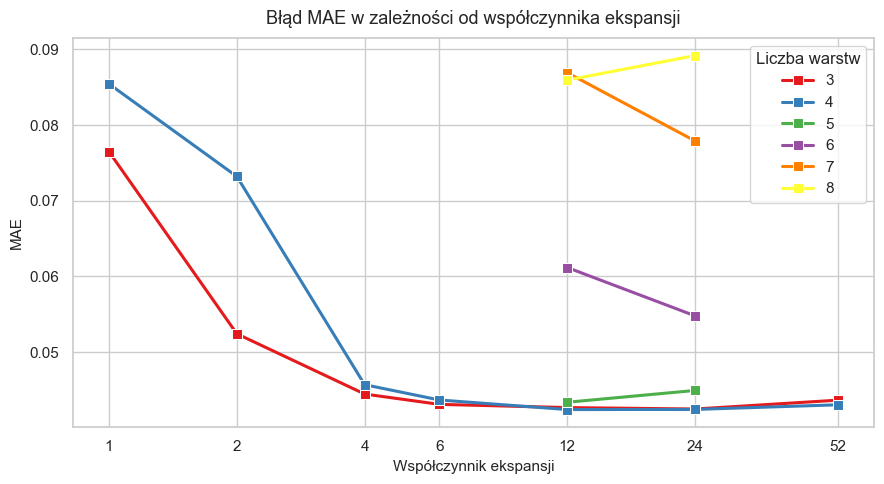

In [15]:
palette_layers = sns.color_palette("Set1", n_colors=df_plot["layers"].nunique())

sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=df_plot,
    x="expansion_factor",
    y="MAE",
    hue="layers_str",
    marker="s",
    linewidth=2.2,
    markersize=7,
    palette=palette_layers
)
plt.title("Błąd MAE w zależności od współczynnika ekspansji", fontsize=13, pad=10)
plt.xlabel("Współczynnik ekspansji", fontsize=11)
plt.ylabel("MAE", fontsize=11)
plt.xscale("log")
plt.xticks(exp_values)
plt.gca().get_xaxis().set_major_formatter(ScalarFormatter())
plt.gca().minorticks_off()
plt.legend(title="Liczba warstw", frameon=True)
plt.tight_layout()
plt.show()

### 3.1. Dwuwymiarowa mapa ciepła jakości architektury (Heatmap 2D)


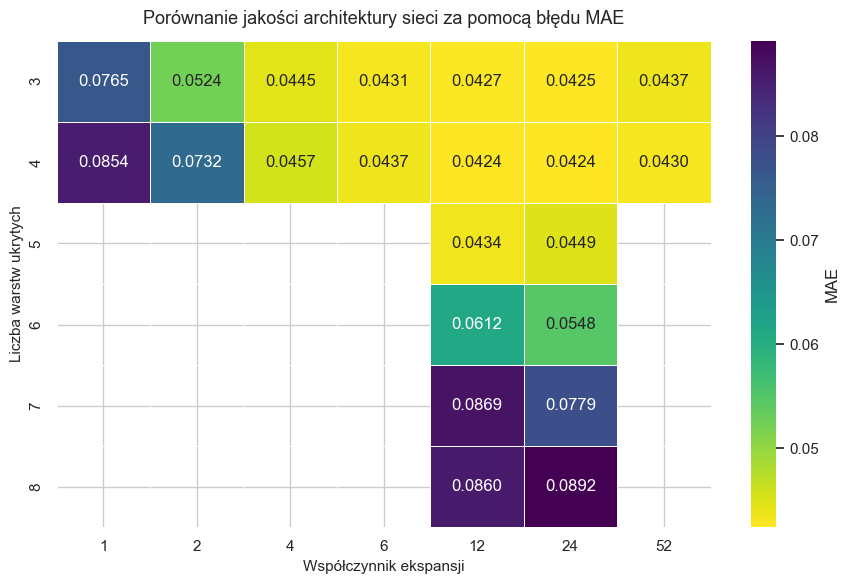

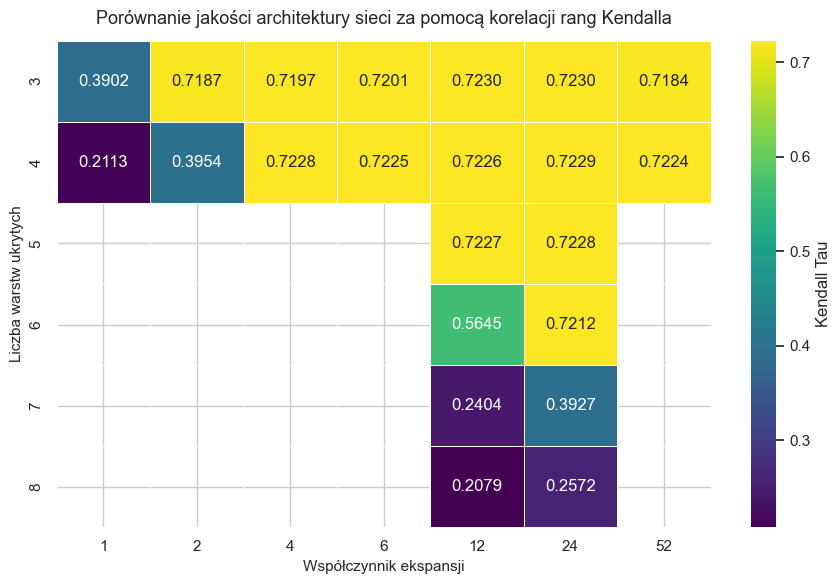

In [16]:
def plot_architecture_heatmap(df_arch, metric="MAE", title="", figsize=(9, 6)):
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=figsize)
    
    pivot_table = df_arch.pivot_table(
        index="layers",
        columns="expansion_factor",
        values=metric,
        aggfunc="mean"
    )
    
    cmap = "viridis_r" if metric.upper() == "MAE" else "viridis"
    
    sns.heatmap(
        pivot_table,
        annot=True,
        fmt=".4f",
        cmap=cmap,
        linewidths=0.6,
        linecolor="white",
        cbar_kws={"label": metric.replace("_", " ")}
    )
    
    plt.title(f"Porównanie jakości architektury sieci za pomocą {title}", fontsize=13, pad=12)
    plt.xlabel("Współczynnik ekspansji", fontsize=11)
    plt.ylabel("Liczba warstw ukrytych", fontsize=11)
    plt.tight_layout()
    plt.show()

plot_architecture_heatmap(df_interaction, metric="MAE", title="błędu MAE")
plot_architecture_heatmap(df_interaction, metric="Kendall_Tau", title="korelacji rang Kendalla")
